# EMIPredict AI: EMI Eligibility and Affordability Predictor
### B.Tech CSE-AIML Student Project Portfolio

This notebook demonstrates the end-to-end Machine Learning pipeline for the **EMIPredict AI** system. The goal of this project is to:
1. Predict whether a user is eligible for an EMI-based loan (Classification problem - Eligible/Not Eligible).
2. Predict the maximum monthly EMI a user can comfortably afford based on their financial profile (Regression problem - Max Affordable EMI).

### Tech Stack:
- **Language**: Python
- **Data Manipulation**: Pandas, NumPy
- **Data Visualization**: Matplotlib, Seaborn
- **Machine Learning**: Scikit-Learn
- **Serialization**: Joblib

## 1. Environment Setup and Data Loading

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plots to display inline
%matplotlib inline
sns.set_theme(style="whitegrid")

# Print current directory to verify structure
print("Current working directory:", os.getcwd())

Current working directory: /tmp/claude-0/-home-user/7a610033-3671-596a-afc5-3c02e2308a8a/scratchpad/emi_nb/notebooks


In [2]:
# Load the dataset
data_path = os.path.join('..', 'data', 'emi_dataset.csv')
if not os.path.exists(data_path):
    # Fallback to local folder if notebook is run in workspace root
    data_path = os.path.join('data', 'emi_dataset.csv')

df = pd.read_csv(data_path)
print(f"Dataset loaded successfully. Shape: {df.shape}")
df.head()

Dataset loaded successfully. Shape: (2500, 10)


,Age,Monthly_Income,Monthly_Expenses,Credit_Score,Existing_Loan_Amount,Existing_EMI,Employment_Type,Dependents,EMI_Eligibility,Max_Affordable_EMI
0,59,65695,23102,667,0,0,Self-Employed,3,0,12100
1,49,68845,39532,639,170000,5000,Salaried,1,0,6600
2,35,127745,70305,668,850000,21200,Self-Employed,2,0,2400
3,63,65622,48794,687,150000,3500,Salaried,1,0,9300
4,28,62587,38101,617,330000,7800,Salaried,0,0,4200


## 2. Exploratory Data Analysis (EDA)

In [3]:
# Summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2500.0,43.1148,12.944213,21.0,32.00,44.0,54.00,65.0
Monthly_Income,2500.0,58215.4476,46893.176420,5001.0,23754.75,43476.0,76831.50,250000.0
Monthly_Expenses,2500.0,32278.2900,25248.307758,4001.0,15229.75,25523.0,41561.75,180661.0
Credit_Score,2500.0,647.7272,117.809057,300.0,567.00,650.0,734.25,850.0
Existing_Loan_Amount,2500.0,138772.0640,235249.393450,0.0,0.00,0.0,190000.00,1960000.0
Existing_EMI,2500.0,3759.1816,6572.496786,0.0,0.00,0.0,5200.00,62200.0
Dependents,2500.0,1.3112,1.161591,0.0,0.00,1.0,2.00,4.0
EMI_Eligibility,2500.0,0.2224,0.415942,0.0,0.00,0.0,0.00,1.0
Max_Affordable_EMI,2500.0,10992.8400,16935.736902,0.0,675.00,4300.0,13600.00,136300.0


In [4]:
# Check for missing values
print("Missing values in each column:")
df.isnull().sum()

Missing values in each column:


Age                     0
Monthly_Income          0
Monthly_Expenses        0
Credit_Score            0
Existing_Loan_Amount    0
Existing_EMI            0
Employment_Type         0
Dependents              0
EMI_Eligibility         0
Max_Affordable_EMI      0
dtype: int64

/tmp/ipykernel_5050/3722147307.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='EMI_Eligibility', data=df, ax=axes[0], palette='Set2')


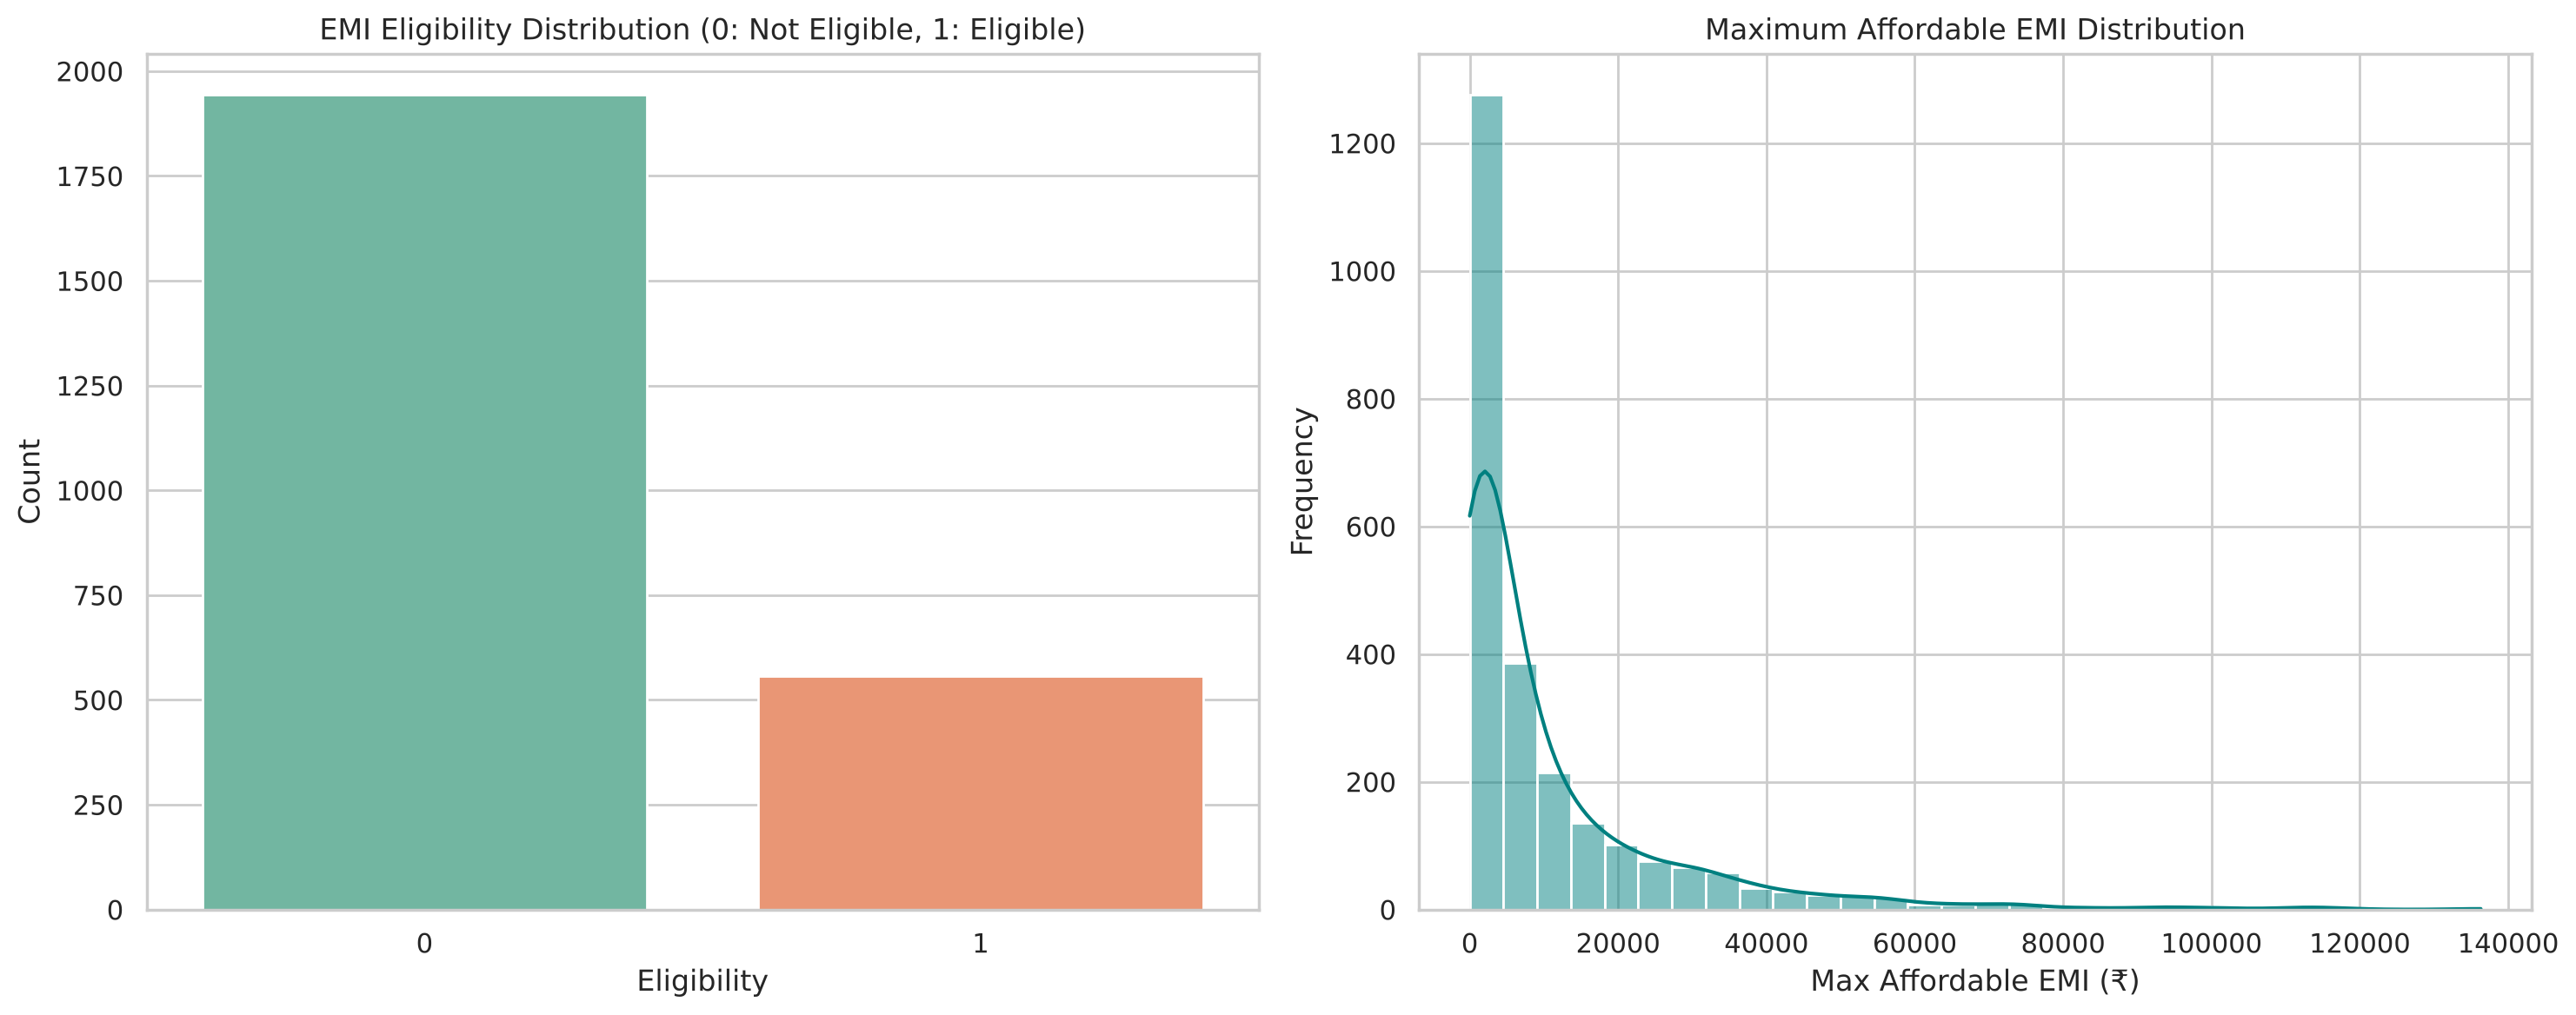

In [5]:
# 2.1 Target Variables Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Class target
sns.countplot(x='EMI_Eligibility', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('EMI Eligibility Distribution (0: Not Eligible, 1: Eligible)')
axes[0].set_xlabel('Eligibility')
axes[0].set_ylabel('Count')

# Regression target
sns.histplot(df['Max_Affordable_EMI'], bins=30, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Maximum Affordable EMI Distribution')
axes[1].set_xlabel('Max Affordable EMI (₹)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

/tmp/ipykernel_5050/2311142803.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='EMI_Eligibility', y='Credit_Score', data=df, ax=axes[0], palette='Set2')


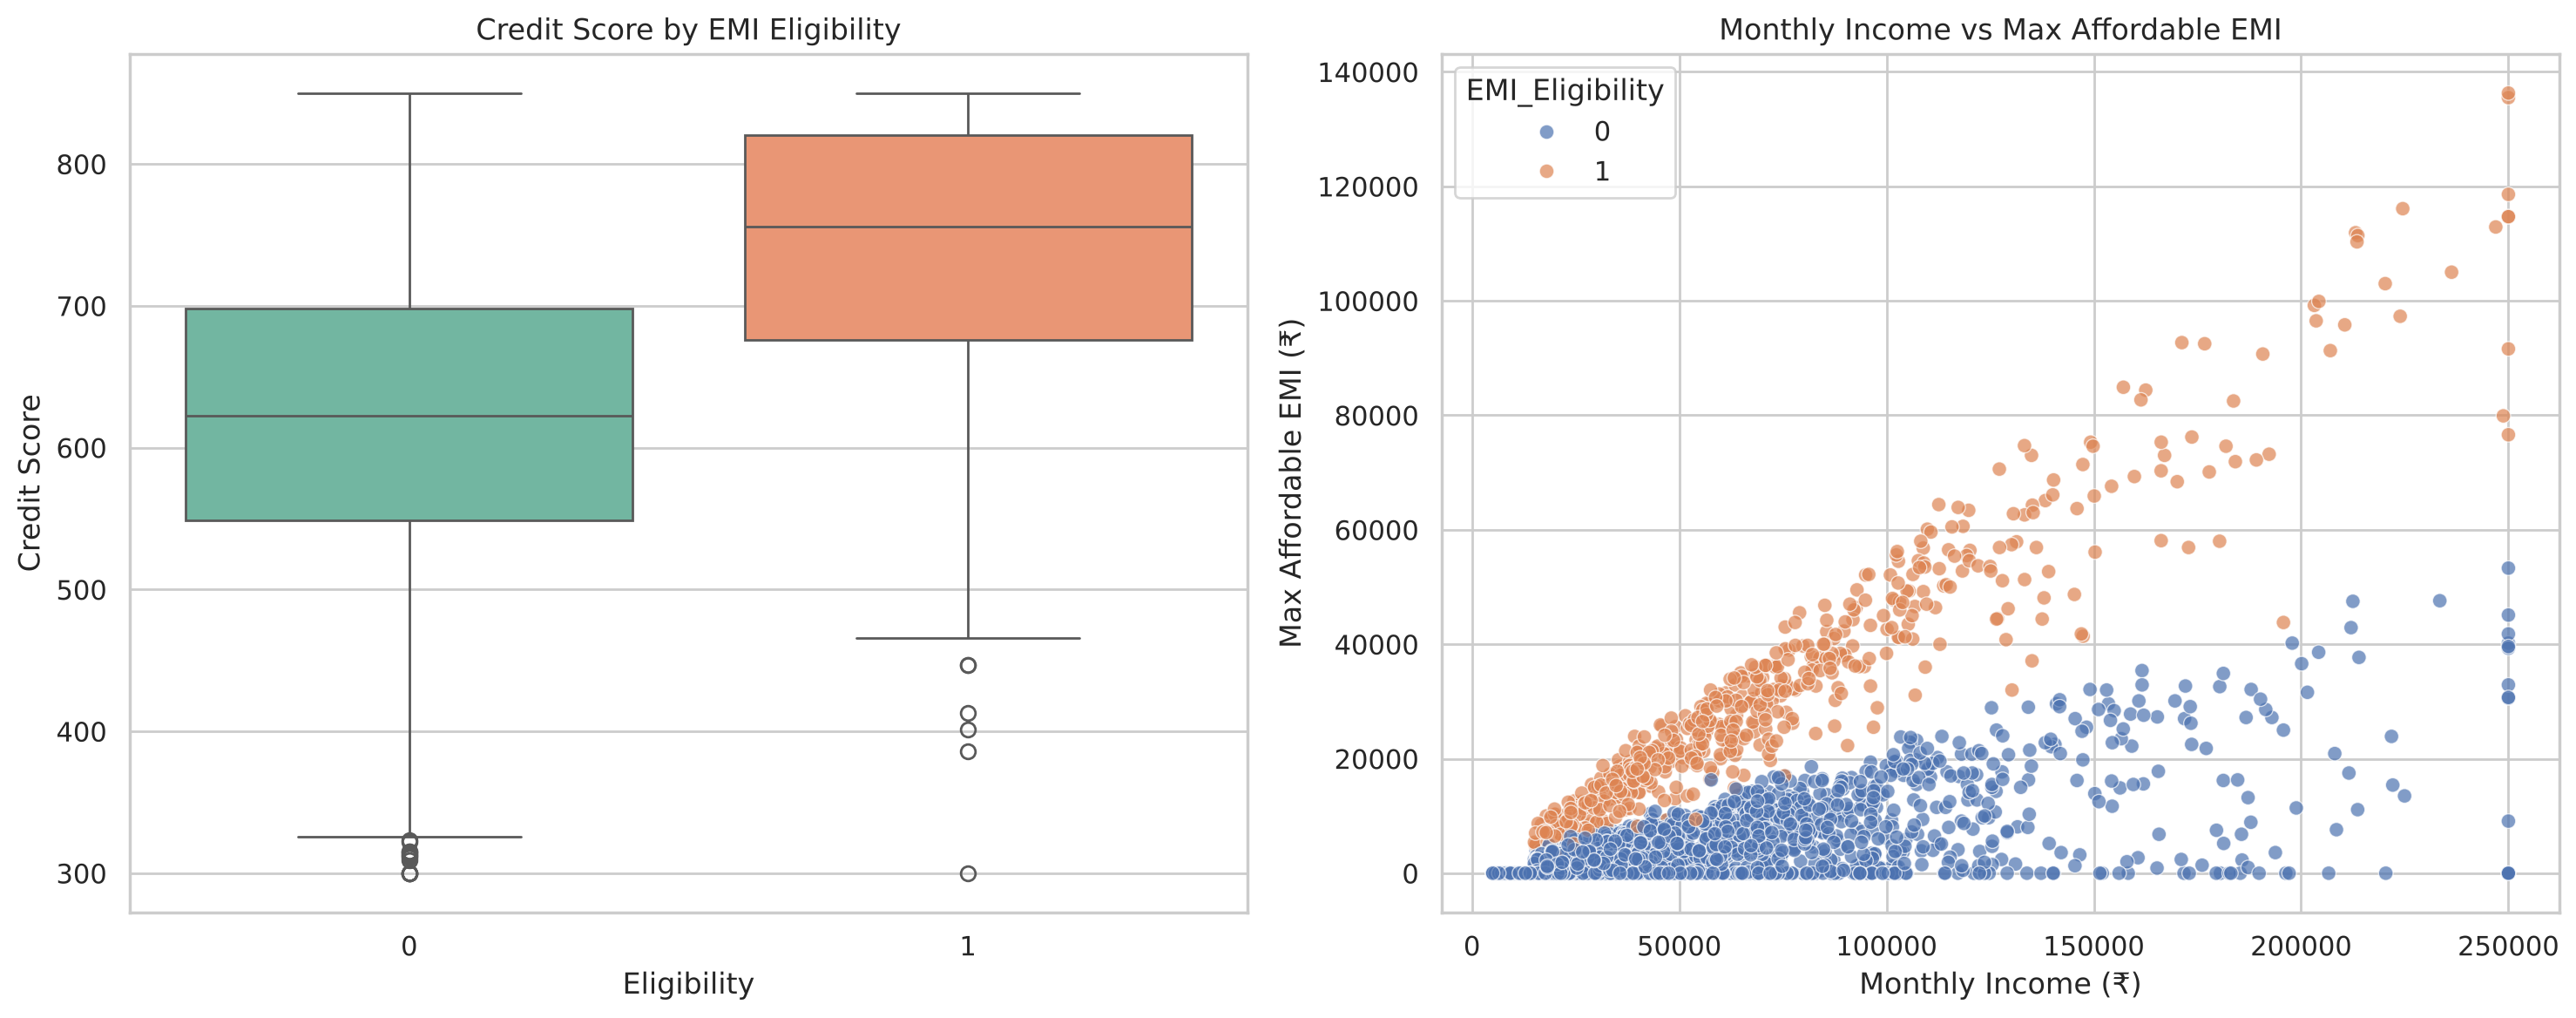

In [6]:
# 2.2 Credit Score & Income Analysis
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Credit Score vs Eligibility
sns.boxplot(x='EMI_Eligibility', y='Credit_Score', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Credit Score by EMI Eligibility')
axes[0].set_xlabel('Eligibility')
axes[0].set_ylabel('Credit Score')

# Income vs Affordability
sns.scatterplot(x='Monthly_Income', y='Max_Affordable_EMI', hue='EMI_Eligibility', data=df, ax=axes[1], alpha=0.7)
axes[1].set_title('Monthly Income vs Max Affordable EMI')
axes[1].set_xlabel('Monthly Income (₹)')
axes[1].set_ylabel('Max Affordable EMI (₹)')

plt.tight_layout()
plt.show()

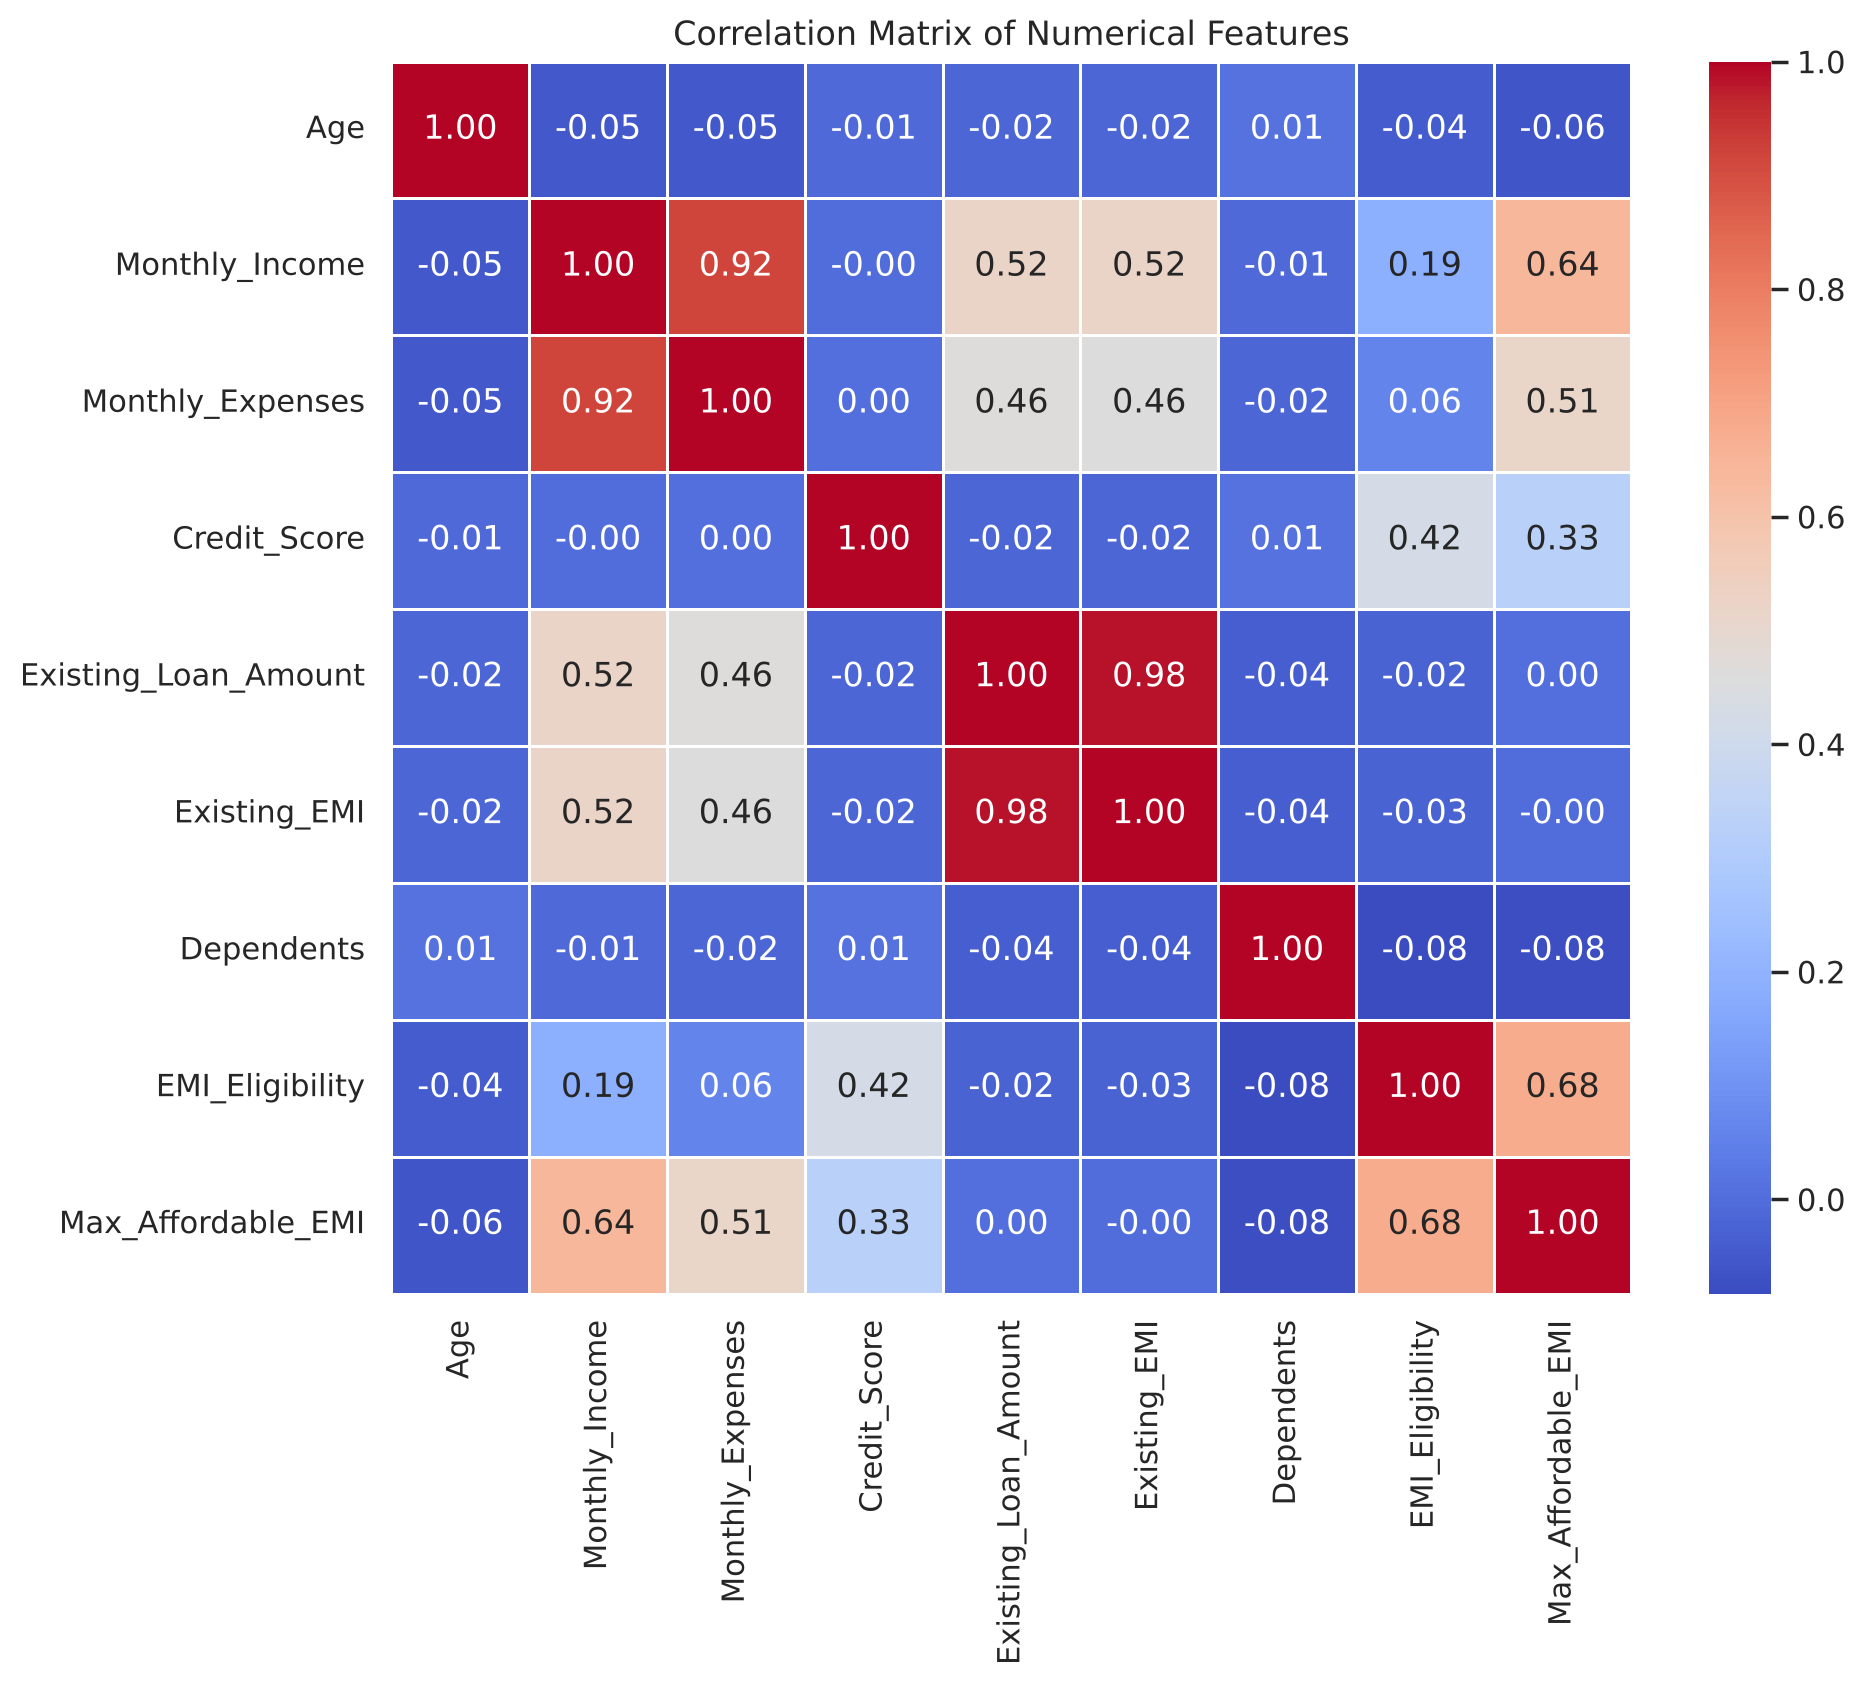

In [7]:
# 2.3 Numerical Features Correlation Heatmap
plt.figure(figsize=(10, 8))
numerical_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## 3. Data Preprocessing and Feature Engineering

In [8]:
# Let's add a few helpful engineered features
# 1. DTI (Debt-to-Income) Ratio
df['DTI_Ratio'] = (df['Monthly_Expenses'] + df['Existing_EMI']) / df['Monthly_Income']

# 2. Disposable Income (Surplus)
df['Disposable_Income'] = df['Monthly_Income'] - df['Monthly_Expenses'] - df['Existing_EMI']

# Check the correlation of the new features with the target variables
df[['DTI_Ratio', 'Disposable_Income', 'EMI_Eligibility', 'Max_Affordable_EMI']].corr()

,DTI_Ratio,Disposable_Income,EMI_Eligibility,Max_Affordable_EMI
DTI_Ratio,1.000000,-0.611739,-0.388303,-0.421441
Disposable_Income,-0.611739,1.000000,0.318992,0.732730
EMI_Eligibility,-0.388303,0.318992,1.000000,0.678318
Max_Affordable_EMI,-0.421441,0.732730,0.678318,1.000000


## 4. Modeling Pipeline & Evaluation

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Split data into independent features and targets
# Note: We drop the targets from X, and we can choose whether to include our engineered features.
# To match the deployment inputs from user forms, we can either calculate DTI inside the pipeline or let the model train on basic inputs.
# Let's train the models on basic features, and let the model figure out the relations (or we can engineer features inside the app).
# Using the raw features makes user inputs easier to handle.
X = df.drop(columns=['EMI_Eligibility', 'Max_Affordable_EMI', 'DTI_Ratio', 'Disposable_Income'])
y_class = df['EMI_Eligibility']
y_reg = df['Max_Affordable_EMI']

num_cols = ['Age', 'Monthly_Income', 'Monthly_Expenses', 'Credit_Score', 
            'Existing_Loan_Amount', 'Existing_EMI', 'Dependents']
cat_cols = ['Employment_Type']

# Define the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
    ]
)

### 4.1 Classification: EMI Eligibility Predictor


=== Logistic Regression ===
Accuracy : 0.8980
Precision: 0.8659
Recall   : 0.6396
F1-Score : 0.7358

Confusion Matrix:
[[378  11]
 [ 40  71]]


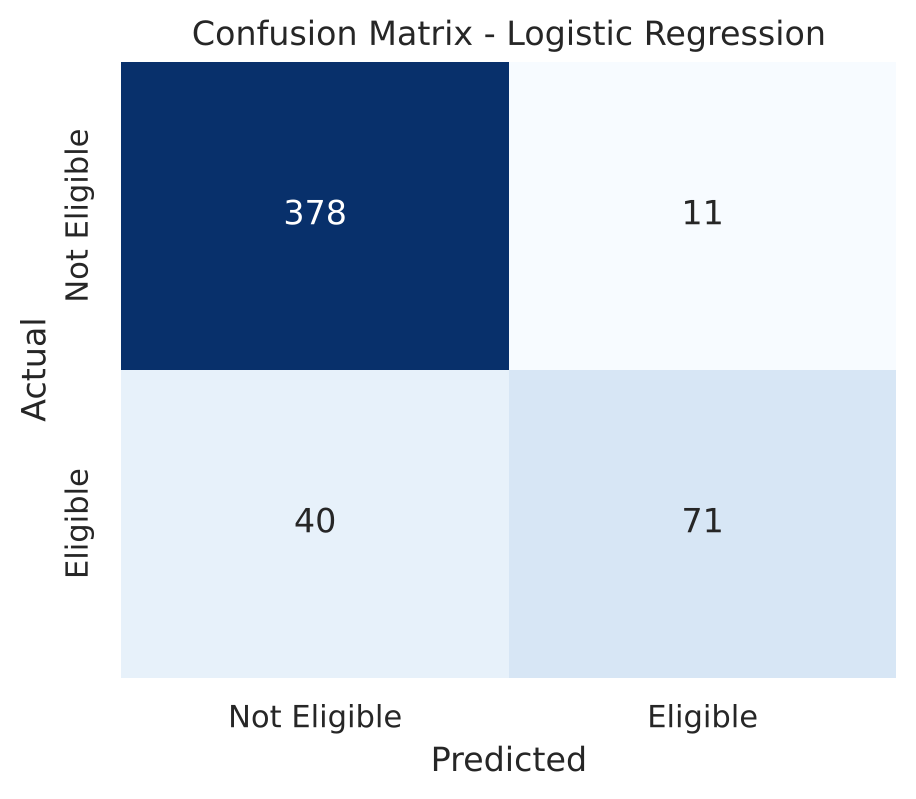


=== Random Forest Classifier ===
Accuracy : 0.8840
Precision: 0.9077
Recall   : 0.5315
F1-Score : 0.6705

Confusion Matrix:
[[383   6]
 [ 52  59]]


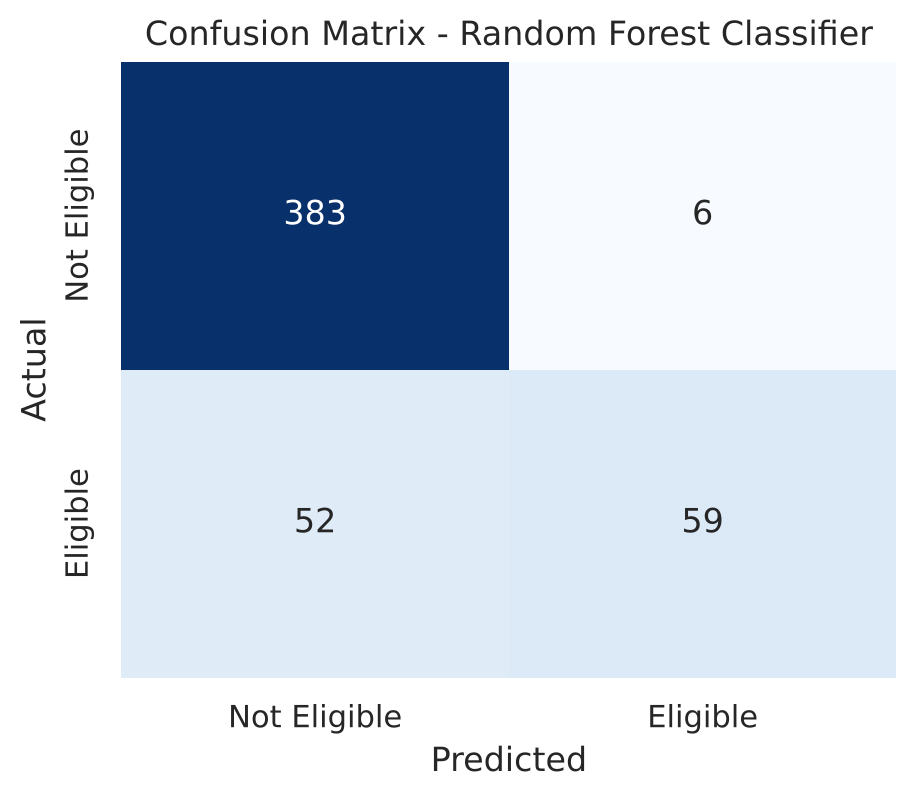

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Train-test split
X_train, X_test, y_train_class, y_test_class = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)

# Create models
clf_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

clf_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10))
])

# Fit Logistic Regression
clf_lr.fit(X_train, y_train_class)
y_pred_lr = clf_lr.predict(X_test)

# Fit Random Forest
clf_rf.fit(X_train, y_train_class)
y_pred_rf = clf_rf.predict(X_test)

# Evaluation function
def print_classification_results(y_true, y_pred, name):
    print(f"\n=== {name} ===")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall   : {recall_score(y_true, y_pred):.4f}")
    print(f"F1-Score : {f1_score(y_true, y_pred):.4f}")
    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    print(cm)
    
    # Plot confusion matrix
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Eligible', 'Eligible'], 
                yticklabels=['Not Eligible', 'Eligible'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

print_classification_results(y_test_class, y_pred_lr, "Logistic Regression")
print_classification_results(y_test_class, y_pred_rf, "Random Forest Classifier")

### 4.2 Regression: EMI Amount Predictor


=== Linear Regression ===
RMSE    : ₹8757.00
MAE     : ₹6161.54
R2 Score: 0.7136


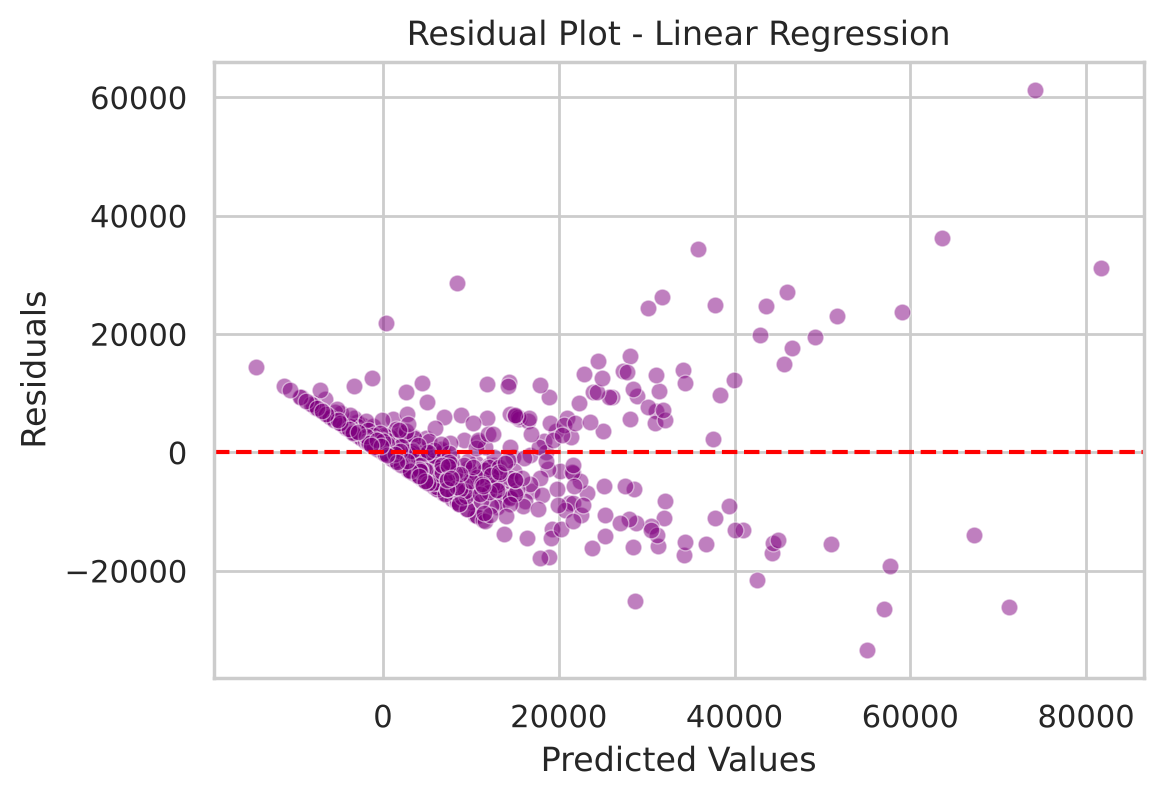


=== Random Forest Regressor ===
RMSE    : ₹6968.81
MAE     : ₹3576.68
R2 Score: 0.8186


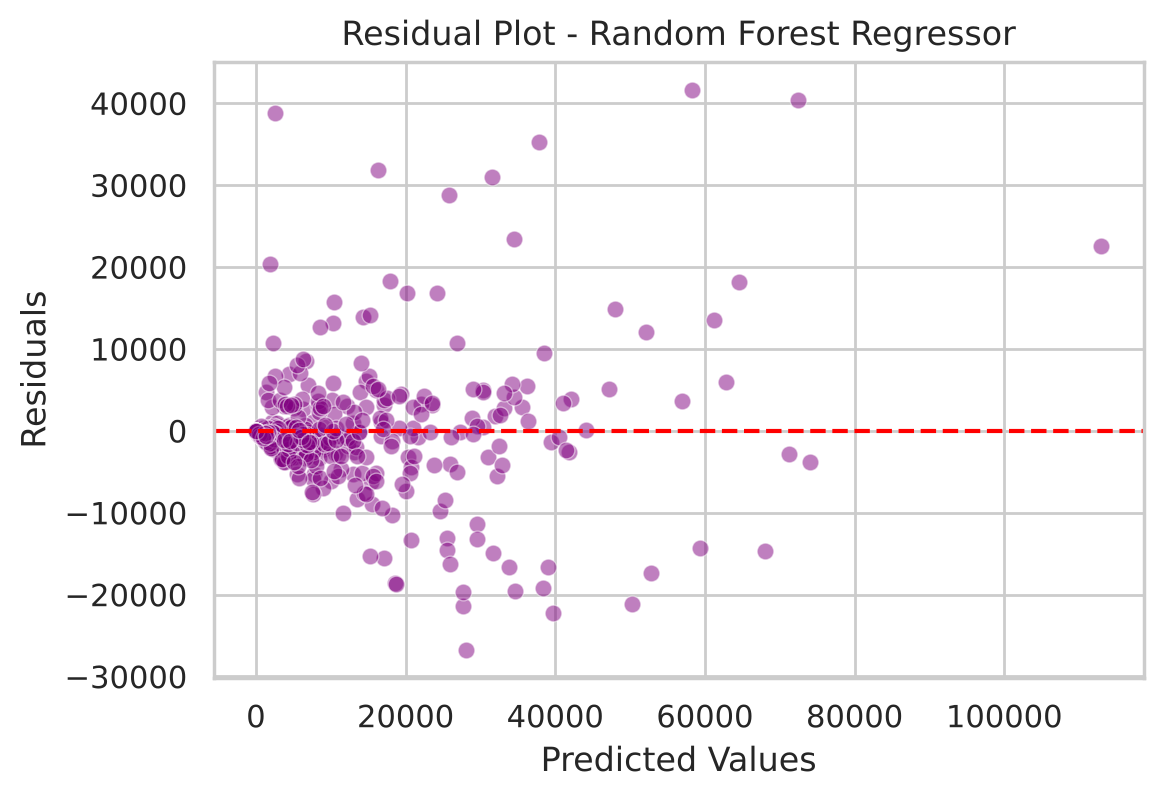

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Train-test split for regression
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42, stratify=y_class
)

# Create regression models
reg_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

reg_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, max_depth=12))
])

# Fit Linear Regression
reg_lr.fit(X_train, y_train_reg)
y_pred_reg_lr = reg_lr.predict(X_test)

# Fit Random Forest Regressor
reg_rf.fit(X_train, y_train_reg)
y_pred_reg_rf = reg_rf.predict(X_test)

# Evaluation function
def print_regression_results(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"\n=== {name} ===")
    print(f"RMSE    : ₹{rmse:.2f}")
    print(f"MAE     : ₹{mae:.2f}")
    print(f"R2 Score: {r2:.4f}")
    
    # Residual plot
    plt.figure(figsize=(6, 4))
    residuals = y_true - y_pred
    sns.scatterplot(x=y_pred, y=residuals, alpha=0.5, color='purple')
    plt.axhline(y=0, color='red', linestyle='--')
    plt.xlabel('Predicted Values')
    plt.ylabel('Residuals')
    plt.title(f'Residual Plot - {name}')
    plt.show()

print_regression_results(y_test_reg, y_pred_reg_lr, "Linear Regression")
print_regression_results(y_test_reg, y_pred_reg_rf, "Random Forest Regressor")

### 4.3 Feature Importance Analysis

/tmp/ipykernel_5050/599419442.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')


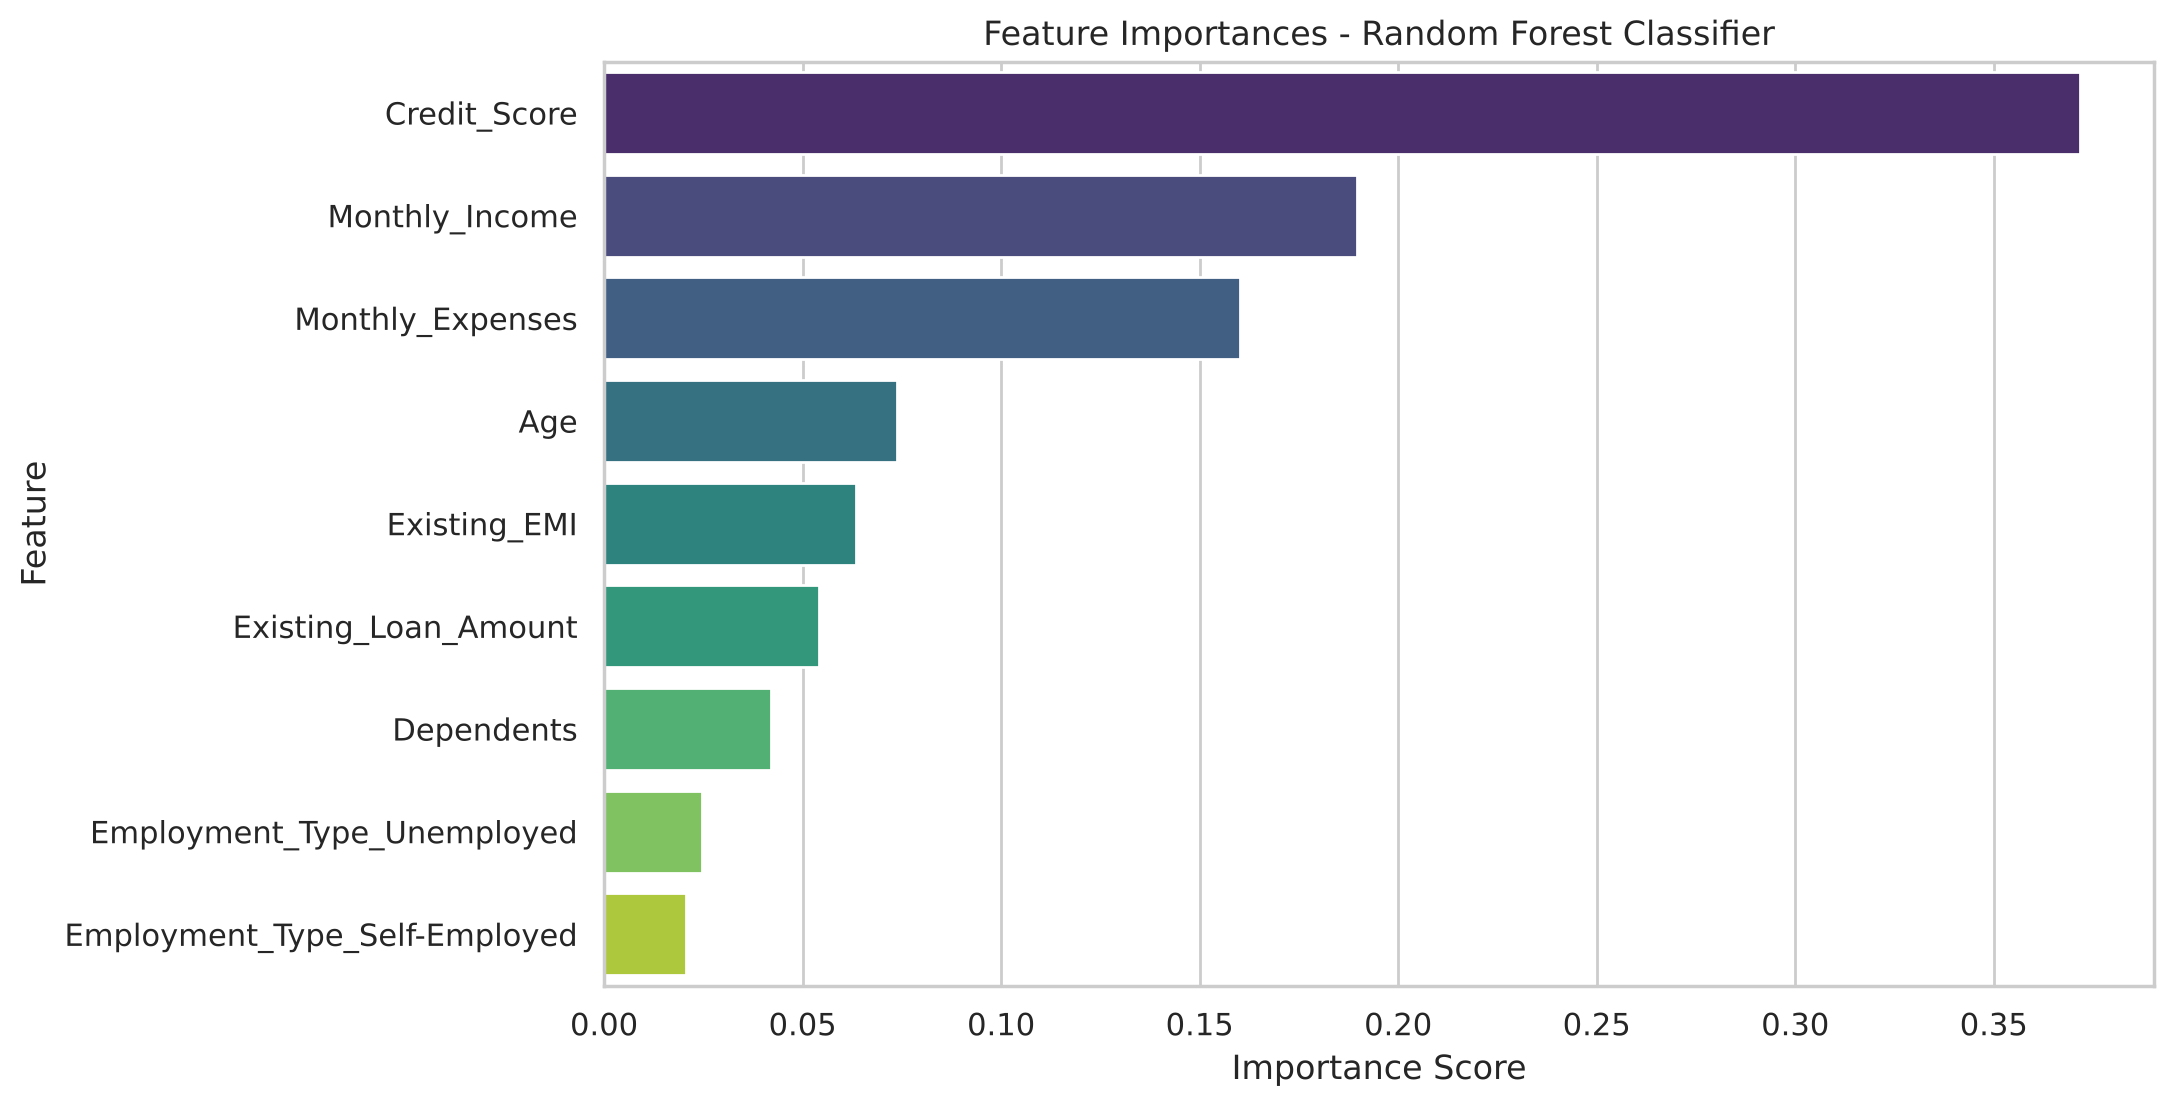

,Feature,Importance
3,Credit_Score,0.371785
1,Monthly_Income,0.189635
2,Monthly_Expenses,0.160106
0,Age,0.073754
5,Existing_EMI,0.063452
4,Existing_Loan_Amount,0.054026
6,Dependents,0.042017
8,Employment_Type_Unemployed,0.024599
7,Employment_Type_Self-Employed,0.020626


In [12]:
# Extract feature names from preprocessing
ohe_categories = clf_rf.named_steps['preprocessor'].named_transformers_['cat'].categories_
encoded_cat_features = []
for col, categories in zip(cat_cols, ohe_categories):
    encoded_cat_features.extend([f"{col}_{cat}" for cat in categories[1:]])
    
feature_names = num_cols + encoded_cat_features

# Get feature importances from Random Forest
importances_clf = clf_rf.named_steps['classifier'].feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances_clf
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
plt.title('Feature Importances - Random Forest Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()
feat_imp_df

## 5. Model Serialization (Saving)

In [13]:
import joblib

# Save the trained pipeline models
models_dir = '../models'
if not os.path.exists(models_dir):
    models_dir = 'models'
    os.makedirs(models_dir, exist_ok=True)

# Save best classifier (Logistic Regression: higher F1 on the test set)
joblib.dump(clf_lr, os.path.join(models_dir, 'best_classifier.joblib'))
# Save best regressor (Random Forest Regressor)
joblib.dump(reg_rf, os.path.join(models_dir, 'best_regressor.joblib'))

print("Best models successfully saved as pipeline joblib files!")

Best models successfully saved as pipeline joblib files!
